> **Demo version with outputs.** This copy was run on **synthetic data only** (5 fictional sites, 180 feedback items, no real people), so the charts and tables can be viewed right here on GitHub. The regular notebook, without outputs, is [`raw_data.ipynb`](raw_data.ipynb). It runs on your local TEST DB.

# Raw data research: Intent AI simulation

<span style="background:#c2352b;color:#fff;padding:4px 12px;border-radius:99px;font-weight:700">SOURCE: TEST</span>

All data in this notebook comes from the local **TEST DB** (`presentation/simulation/data/test.db`), not production. Every table has a `SOURCE` column with the value `TEST`.

> ⚠️ **Raw personal data:** transcripts, recordings and anonymous identifiers of end users. The connection is **read-only**. **Before a commit, run `Clear All Outputs`** so that personal data doesn't end up in git.

**How to run:** select a Python kernel (top right), then `Run All`.

In [1]:
# --- Setup: read-only connection to the TEST DB ---
import json
import sqlite3
from pathlib import Path

import pandas as pd
from IPython.display import Audio, HTML, display

SOURCE = "TEST"
ROW_LIMIT = 5000

# The notebook sits in presentation/simulation/notebooks/ → look upward for the simulation folder
SIM_DIR = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "sites.json").exists() and (p / "server.js").exists()),
               Path.cwd().parent)
DB_PATH = SIM_DIR / "data" / "test.db"
AUDIO_DIR = SIM_DIR / "data" / "audio"
assert DB_PATH.exists(), f"TEST DB not found: {DB_PATH} (run npm start in presentation/simulation/ at least once)"

# mode=ro → SQLite blocks any write at the engine level, not just by text filtering
# isolation_level=None → autocommit: no transaction is held open, so the server is never blocked
conn = sqlite3.connect(f"{DB_PATH.as_uri()}?mode=ro", uri=True, isolation_level=None)

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 120)


def sql(query: str, params: tuple = ()) -> pd.DataFrame:
    """Runs a read query against the TEST DB and returns a DataFrame with SOURCE=TEST as the first column."""
    df = pd.read_sql_query(query, conn, params=params)
    if len(df) > ROW_LIMIT:
        print(f"Showing the first {ROW_LIMIT} of {len(df)} rows")
        df = df.head(ROW_LIMIT)
    df.insert(0, "SOURCE", SOURCE)
    return df


display(HTML(f'<b style="color:#c2352b">SOURCE: {SOURCE}</b> · {DB_PATH} · read-only'))

In [2]:
# Check: the connection really is read-only (a write attempt should be blocked)
try:
    conn.execute("DELETE FROM feedback WHERE 1 = 0")
    print("⚠️  Warning: the connection is not read-only!")
except sqlite3.OperationalError as e:
    print(f"✅ Read-only: {e}")

✅ Read-only: attempt to write a readonly database


## 1. Overview by site (customer)
`active = 0` means a site that was removed from `sites.json`. Its data is kept in the DB but hidden from the dashboard.

In [3]:
sql("""
SELECT o.slug, o.name, o.industry, o.active,
       COUNT(f.id)                              AS total,
       SUM(f.type = 'voice')                    AS voice,
       SUM(f.type = 'text')                     AS text,
       COUNT(DISTINCT f.end_user_id)            AS end_users,
       MIN(f.created_at)                        AS first_feedback,
       MAX(f.created_at)                        AS last_feedback
FROM organizations o
JOIN products p      ON p.organization_id = o.id
LEFT JOIN feedback f ON f.product_id = p.id
GROUP BY o.id
ORDER BY total DESC
""")

,SOURCE,slug,name,industry,active,total,voice,text,end_users,first_feedback,last_feedback
0,TEST,market,מרקט פלוס,קמעונאות,1,65,16,49,31,2026-10-24T03:31:27.000Z,2026-11-06T18:09:26.000Z
1,TEST,wings,כנף טיסות,תעופה,1,38,8,30,27,2026-10-24T09:18:43.000Z,2026-11-06T17:32:51.000Z
2,TEST,news,חדשות היום,מדיה וחדשות,1,31,9,22,24,2026-10-24T09:07:34.000Z,2026-11-06T18:10:51.000Z
3,TEST,pharma,פארם פלוס,פארם ובריאות,1,25,6,19,20,2026-10-24T18:06:20.000Z,2026-11-06T19:51:41.000Z
4,TEST,telco,תקשורת פלוס,תקשורת,1,21,5,16,17,2026-10-24T18:36:51.000Z,2026-11-05T07:00:08.000Z


## 2. All raw data, record by record
Every field as it's stored in the DB, joined with the site and the end user. The `raw` table is available for further analysis in pandas.

In [4]:
# Newer fields may be missing from an older DB (the server adds them on start; this connection is read-only)
_fb_cols = {r[1] for r in conn.execute("PRAGMA table_info(feedback)")}
_optional = ["consent_version", "consent_at", "browser", "os", "device", "language", "time_zone", "country", "ip_hash", "feedback_lang"]
_opt_sql = ", ".join(f"f.{c}" if c in _fb_cols else f"NULL AS {c}" for c in _optional)
_missing = [c for c in _optional if c not in _fb_cols]
if _missing:
    print(f"Note: these fields don't exist yet in the DB (restart the server): {', '.join(_missing)}")

raw = sql(f"""
SELECT f.id, o.slug AS site, o.name AS site_name, o.active AS site_active,
       f.type, f.content, f.rating, f.sentiment, f.category,
       f.audio_path, f.audio_duration_ms, f.page_url, f.created_at,
       {_opt_sql},
       e.external_id AS end_user, e.first_seen AS end_user_first_seen, e.last_seen AS end_user_last_seen,
       p.id AS product_id, f.end_user_id AS end_user_row_id
FROM feedback f
JOIN products p      ON p.id = f.product_id
JOIN organizations o ON o.id = p.organization_id
JOIN end_users e     ON e.id = f.end_user_id
ORDER BY f.created_at DESC
""")
# Optional: exclude automated test rows (content starting with "QA-") from the analysis
EXCLUDE_QA = False
if EXCLUDE_QA:
    raw = raw[~raw["content"].fillna("").str.startswith("QA-")].reset_index(drop=True)

print(f"{len(raw)} records · {raw['end_user'].nunique()} distinct users · SOURCE={SOURCE}")
raw.head(20)

Note: these fields don't exist yet in the DB (restart the server): feedback_lang
180 records · 53 distinct users · SOURCE=TEST


,SOURCE,id,site,site_name,site_active,type,content,rating,sentiment,category,audio_path,audio_duration_ms,page_url,created_at,consent_version,consent_at,browser,os,device,language,time_zone,country,ip_hash,feedback_lang,end_user,end_user_first_seen,end_user_last_seen,product_id,end_user_row_id
0,TEST,c304eec7-e54f-4b5b-94b7-8b4e81540b5d,pharma,פארם פלוס,1,text,המרשם לא היה מוכן בבית המרקחת,NaN,neutral,pharmacy,NaN,NaN,https://pharma.example/,2026-11-06T19:51:41.000Z,2026-11-06.2,2026-11-06T19:51:41.000Z,Chrome,Android,mobile,he-IL,Asia/Jerusalem,IL,c307a48f48b41a18,None,b876d188-aa16-4fb8-b5f1-c7373df8f272,2026-11-06T22:30:39.473Z,2026-11-06T22:30:39.473Z,e1c28df2-d12c-4786-b9a3-10dc1ca39cfc,07a701e3-193e-4cc3-be8a-a5675b9bf209
1,TEST,51a30c3d-718e-4f11-820b-d77f2203001a,news,חדשות היום,1,text,מודעה קופצת שאי אפשר לסגור,3.0,neutral,content,NaN,NaN,https://news.example/,2026-11-06T18:10:51.000Z,2026-11-06.2,2026-11-06T18:10:51.000Z,Chrome,Windows,desktop,he-IL,Asia/Jerusalem,IL,70a03bf48ca9a466,None,3270a122-598f-440d-1198-397ea9f4c207,2026-11-06T22:30:39.472Z,2026-11-06T22:30:39.472Z,d69a6fcb-2f94-46bc-a2cb-48e033ae9cc0,d9598011-abed-4bda-b984-c8e641a45a57
2,TEST,d219262a-bca5-41de-af6f-dfc12a48127d,market,מרקט פלוס,1,text,המחירים יקרים לעומת הסניף,1.0,negative,prices,NaN,NaN,https://market.example/,2026-11-06T18:09:26.000Z,2026-11-06.2,2026-11-06T18:09:26.000Z,Edge,Windows,desktop,he-IL,Asia/Jerusalem,IL,363eb5f5498fd0df,None,edfc7551-7315-484a-ff1e-dbd7ced52600,2026-11-06T22:30:39.266Z,2026-11-06T22:30:39.471Z,6ec3e349-46b4-4681-b637-6fafbc3fd79e,5768842f-eb12-4cfb-95cb-2fc2f4fa6364
3,TEST,e8c7fabb-a576-46ba-a82a-ce085a60a323,pharma,פארם פלוס,1,text,המרשם לא היה מוכן בבית המרקחת,NaN,neutral,pharmacy,NaN,NaN,https://pharma.example/,2026-11-06T17:36:28.000Z,2026-11-06.2,2026-11-06T17:36:28.000Z,Edge,Windows,desktop,he-IL,Asia/Jerusalem,IL,d6f7957a8e225216,None,12a58b3b-0f86-49b6-a735-7139b51cf292,2026-11-06T22:30:39.470Z,2026-11-06T22:30:39.470Z,e1c28df2-d12c-4786-b9a3-10dc1ca39cfc,9962fc13-fbb0-433d-aa8f-62b351e02ddc
4,TEST,21ec2096-348e-465e-80f0-f6da13408939,wings,כנף טיסות,1,text,"המראה בזמן ונחיתה רכה, מעולה",5.0,positive,travel,NaN,NaN,https://wings.example/,2026-11-06T17:32:51.000Z,2026-11-06.2,2026-11-06T17:32:51.000Z,Edge,Windows,desktop,he-IL,Asia/Jerusalem,IL,c395b8d3673dab80,None,40e1b290-f634-4933-01cd-5deb3a018434,2026-11-06T22:30:39.469Z,2026-11-06T22:30:39.469Z,3da352f7-6cdb-44a3-affa-7b1c3e9b3b0a,2d0f0d0a-3d36-4f7b-b0b9-0add297719a2
5,TEST,a5ea35b4-5060-4c65-a88d-8cf73ca17e90,market,מרקט פלוס,1,text,השליח לא הגיע בזמן שנקבע,NaN,negative,delivery,NaN,NaN,https://market.example/,2026-11-06T17:14:21.000Z,2026-11-06.2,2026-11-06T17:14:21.000Z,Edge,Windows,desktop,he-IL,Asia/Jerusalem,IL,2be4da511fb48186,None,fd02c11e-494c-4b07-f116-cb4717682c4b,2026-11-06T22:30:39.343Z,2026-11-06T22:30:39.468Z,6ec3e349-46b4-4681-b637-6fafbc3fd79e,f9b744c7-dbf9-4781-a080-6d5aff29bba1
6,TEST,821487ce-7788-4c39-a699-f100c7cec504,wings,כנף טיסות,1,voice,הטיסה התעכבה שלוש שעות בלי הסבר,NaN,negative,travel,demo-voice-2-1.wav,3481.0,https://wings.example/,2026-11-06T13:09:49.000Z,2026-11-06.2,2026-11-06T13:09:49.000Z,Chrome,Windows,desktop,he-IL,Asia/Jerusalem,IL,b037da8e2ecbbf66,None,5d47eed4-3bd1-4904-813d-2ab556a735de,2026-11-06T22:30:39.300Z,2026-11-06T22:30:39.467Z,3da352f7-6cdb-44a3-affa-7b1c3e9b3b0a,3c0b267c-aec6-4102-b695-f24461726a2a
7,TEST,392f691b-e365-46d1-a47a-f04023536962,market,מרקט פלוס,1,voice,"המשלוח הגיע מהר והכל היה טרי, תודה",NaN,positive,delivery,demo-voice-1-1.wav,5669.0,https://market.example/,2026-11-06T12:29:15.000Z,2026-11-06.2,2026-11-06T12:29:15.000Z,Safari,iOS,mobile,he-IL,Asia/Jerusalem,IL,1f1a82cea0293462,None,ce26bc86-ff2a-4397-86a9-d13d1d5a5c32,2026-11-06T22:30:39.301Z,2026-11-06T22:30:39.466Z,6ec3e349-46b4-4681-b637-6fafbc3fd79e,77fb7e1d-d8ea-43e6-9117-5693c120e866
8,TEST,68619b5c-0df7-4daf-9bdb-44ca8dfb35d2,market,מרקט פלוס,1,text,"האתר נתקע בתשלום, ממש מתסכל",NaN,negative,checkout,NaN,NaN,https://mark

## 3. A single record
`record(n)` shows record number `n` from the `raw` table (0 = the newest), or a record by its `id`. It displays all the raw fields, a player if there's a recording, and the record as JSON.

In [5]:
def record(key=0):
    """Shows a single record by its position in raw (int) or by its feedback id (str)."""
    if isinstance(key, int):
        if not 0 <= key < len(raw):
            raise IndexError(f"There are {len(raw)} records (0–{len(raw) - 1})")
        row = raw.iloc[key]
    else:
        match = raw[raw["id"] == key]
        if match.empty:
            raise KeyError(f"Record {key} not found")
        row = match.iloc[0]

    display(HTML(f'<h4 style="margin:4px 0">Record {row["id"]} '
                 f'<span style="background:#c2352b;color:#fff;padding:2px 10px;border-radius:99px;font-size:12px">SOURCE: {row["SOURCE"]}</span></h4>'))
    display(row.to_frame("value"))

    audio_path = row.get("audio_path")
    if isinstance(audio_path, str) and audio_path:
        f = AUDIO_DIR / Path(audio_path).name
        if f.exists():
            display(Audio(filename=str(f)))
        else:
            print(f"(The recording file no longer exists: {f.name}, possibly deleted by retention or a deletion request)")

    print(json.dumps({k: (None if pd.isna(v) else v) for k, v in row.to_dict().items()}, ensure_ascii=False, indent=2, default=str))


record(0)  # the newest record. Try: record(3) or record("<id>")

,value
SOURCE,TEST
id,c304eec7-e54f-4b5b-94b7-8b4e81540b5d
site,pharma
site_name,פארם פלוס
site_active,1
type,text
content,המרשם לא היה מוכן בבית המרקחת
rating,NaN
sentiment,neutral
category,pharmacy


{
  "SOURCE": "TEST",
  "id": "c304eec7-e54f-4b5b-94b7-8b4e81540b5d",
  "site": "pharma",
  "site_name": "פארם פלוס",
  "site_active": 1,
  "type": "text",
  "content": "המרשם לא היה מוכן בבית המרקחת",
  "rating": null,
  "sentiment": "neutral",
  "category": "pharmacy",
  "audio_path": null,
  "audio_duration_ms": null,
  "page_url": "https://pharma.example/",
  "created_at": "2026-11-06T19:51:41.000Z",
  "consent_version": "2026-11-06.2",
  "consent_at": "2026-11-06T19:51:41.000Z",
  "browser": "Chrome",
  "os": "Android",
  "device": "mobile",
  "language": "he-IL",
  "time_zone": "Asia/Jerusalem",
  "country": "IL",
  "ip_hash": "c307a48f48b41a18",
  "feedback_lang": null,
  "end_user": "b876d188-aa16-4fb8-b5f1-c7373df8f272",
  "end_user_first_seen": "2026-11-06T22:30:39.473Z",
  "end_user_last_seen": "2026-11-06T22:30:39.473Z",
  "product_id": "e1c28df2-d12c-4786-b9a3-10dc1ca39cfc",
  "end_user_row_id": "07a701e3-193e-4cc3-be8a-a5675b9bf209"
}


## 4. Exploration

In [6]:
# Filter by site: replace "shufersal" with elal / ynet / superpharm / partner
SITE = "shufersal"
raw[raw["site"] == SITE][["SOURCE", "created_at", "type", "content", "rating", "sentiment", "category"]]

,SOURCE,created_at,type,content,rating,sentiment,category


In [7]:
# Voice feedback without a transcript (the browser's transcription didn't return text)
raw[(raw["type"] == "voice") & (raw["content"].isna())][["SOURCE", "site", "created_at", "audio_path", "audio_duration_ms"]]

,SOURCE,site,created_at,audio_path,audio_duration_ms


In [8]:
# Sentiment distribution by site
sentiment = pd.crosstab(raw["site"], raw["sentiment"], margins=True, margins_name="Total")
sentiment.insert(0, "SOURCE", SOURCE)
sentiment

sentiment,SOURCE,negative,neutral,positive,Total
site,,,,,
market,TEST,40,0,25,65
news,TEST,2,16,13,31
pharma,TEST,0,8,17,25
telco,TEST,7,6,8,21
wings,TEST,19,11,8,38
Total,TEST,68,41,71,180


In [9]:
# Category distribution by site
categories = pd.crosstab(raw["category"], raw["site"])
categories.insert(0, "SOURCE", SOURCE)
categories

site,SOURCE,market,news,pharma,telco,wings
category,,,,,,
billing,TEST,0,0,0,2,0
checkout,TEST,19,0,0,0,3
connectivity,TEST,0,0,0,14,0
content,TEST,0,21,0,0,0
delivery,TEST,21,0,4,0,0
other,TEST,0,8,0,0,2
pharmacy,TEST,0,0,14,0,0
prices,TEST,11,0,7,1,7
service,TEST,6,0,0,4,0


In [10]:
# Activity over time (feedback per day)
daily = raw.assign(day=pd.to_datetime(raw["created_at"]).dt.date).groupby(["day", "site"]).size().unstack(fill_value=0)
daily.insert(0, "SOURCE", SOURCE)
daily

site,SOURCE,market,news,pharma,telco,wings
day,,,,,,
2026-10-24,TEST,5,1,1,1,4
2026-10-25,TEST,2,2,2,1,1
2026-10-26,TEST,4,4,3,3,5
2026-10-27,TEST,3,1,1,2,0
2026-10-28,TEST,3,6,2,1,1
2026-10-29,TEST,9,2,1,1,1
2026-10-30,TEST,6,0,1,0,4
2026-10-31,TEST,5,2,2,2,1
2026-11-01,TEST,5,4,3,2,2


In [11]:
# Free SQL query: write any read query (writes are blocked)
sql("""
SELECT o.name AS site, f.category, COUNT(*) AS n, ROUND(AVG(f.rating), 2) AS avg_rating
FROM feedback f
JOIN products p      ON p.id = f.product_id
JOIN organizations o ON o.id = p.organization_id
GROUP BY o.name, f.category
ORDER BY n DESC
""")

,SOURCE,site,category,n,avg_rating
0,TEST,כנף טיסות,travel,26,2.70
1,TEST,חדשות היום,content,21,3.00
2,TEST,מרקט פלוס,delivery,21,2.33
3,TEST,מרקט פלוס,checkout,19,1.20
4,TEST,פארם פלוס,pharmacy,14,4.00
5,TEST,תקשורת פלוס,connectivity,14,2.33
6,TEST,מרקט פלוס,prices,11,3.33
7,TEST,חדשות היום,other,8,4.33
8,TEST,מרקט פלוס,site,8,1.00
9,TEST,כנף טיסות,prices,7,2.00


## 5. Trend charts
Every chart comes with a data table underneath (accessibility, and exact numbers). Colors follow the site (a fixed order from `sites.json`), not its rank. Hours are shown in Israel time. Hidden sites (`site_active = 0`) are excluded from the charts.

In [12]:
# --- Chart style (reference palette from the dataviz guidelines, validated for color blindness) ---
import re
from collections import Counter

import matplotlib
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np
from matplotlib.ticker import MaxNLocator

SURFACE, INK, INK_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e0"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ = mcolors.LinearSegmentedColormap.from_list("seq_blue", ["#cde2fb", "#86b6ef", "#2a78d6", "#1c5cab", "#0d366b"])
NEG, NEU, POS = "#e34948", "#f0efec", "#2a78d6"   # diverging: red ↔ gray ↔ blue
TZ = "Asia/Jerusalem"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": ["Segoe UI", "Arial", "DejaVu Sans"], "font.size": 10,
    "text.color": INK, "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.edgecolor": GRID, "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "right",
})

# Hebrew in charts: matplotlib 3.11+ lays out right-to-left text on its own (an extra conversion would mirror it);
# older versions need bidi reordering. Pick the right method automatically.
_mpl = tuple(int(x) for x in matplotlib.__version__.split(".")[:2])
if _mpl >= (3, 11):
    h = str
else:
    try:
        from bidi import get_display as h
    except ImportError:
        h = lambda t: str(t)[::-1]  # rough fallback for pure Hebrew labels
print(f"matplotlib {matplotlib.__version__} · Hebrew in charts: {'native' if h is str else 'bidi conversion'}")

SITE_ORDER = [s["slug"] for s in json.loads((SIM_DIR / "sites.json").read_text(encoding="utf-8"))]
SITE_COLOR = {slug: SERIES[i] for i, slug in enumerate(SITE_ORDER)}
SITE_NAME = dict(zip(raw["site"], raw["site_name"]))

active = raw[raw["site_active"] == 1].copy()
active["local_time"] = pd.to_datetime(active["created_at"], utc=True).dt.tz_convert(TZ)
active["hour"] = active["local_time"].dt.hour
active["day"] = active["local_time"].dt.date
sites_present = [s for s in SITE_ORDER if s in set(active["site"])]


def source_tag(ax):
    ax.text(0, 1.02, f"SOURCE: {SOURCE}", transform=ax.transAxes, ha="left", va="bottom",
            fontsize=8, color="#c2352b", fontweight="bold")


def table(df):
    out = df.copy()
    out.insert(0, "SOURCE", SOURCE)
    display(out)


print(f"{len(active)} records from {len(sites_present)} active sites · SOURCE={SOURCE}")

matplotlib 3.11.1 · Hebrew in charts: native
180 records from 5 active sites · SOURCE=TEST


### 5.1 Hours of the day: when do users send feedback?

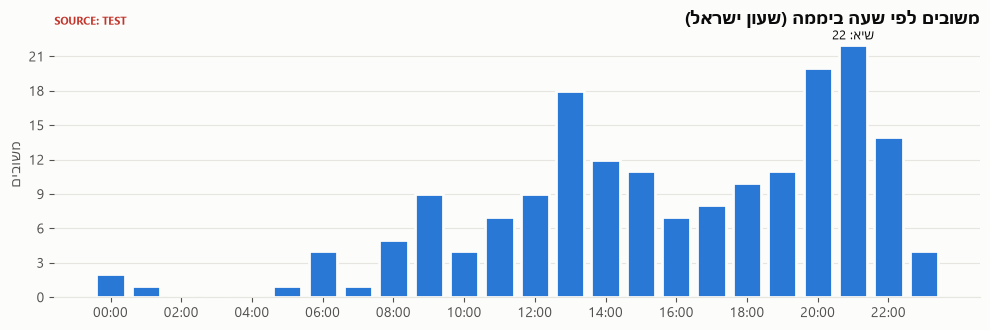

hour,SOURCE,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
feedback,TEST,2,1,0,0,0,1,4,1,5,9,4,7,9,18,12,11,7,8,10,11,20,22,14,4


In [13]:
by_hour = active.groupby("hour").size().reindex(range(24), fill_value=0)

fig, ax = plt.subplots(figsize=(10, 3.4))
ax.bar(by_hour.index, by_hour.values, width=0.8, color=SERIES[0], edgecolor=SURFACE, linewidth=2)
ax.set_xticks(range(0, 24, 2), [f"{h_:02d}:00" for h_ in range(0, 24, 2)])
ax.set_ylabel(h("משובים")); ax.yaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_title(h("משובים לפי שעה ביממה (שעון ישראל)"))
ax.grid(axis="x", visible=False)
peak = int(by_hour.idxmax())
ax.annotate(h(f"שיא: {by_hour.max()}"), (peak, by_hour.max()), xytext=(0, 4), textcoords="offset points",
            ha="center", fontsize=9, color=INK)
source_tag(ax)
plt.tight_layout(); plt.show()
table(by_hour.rename("feedback").to_frame().T)

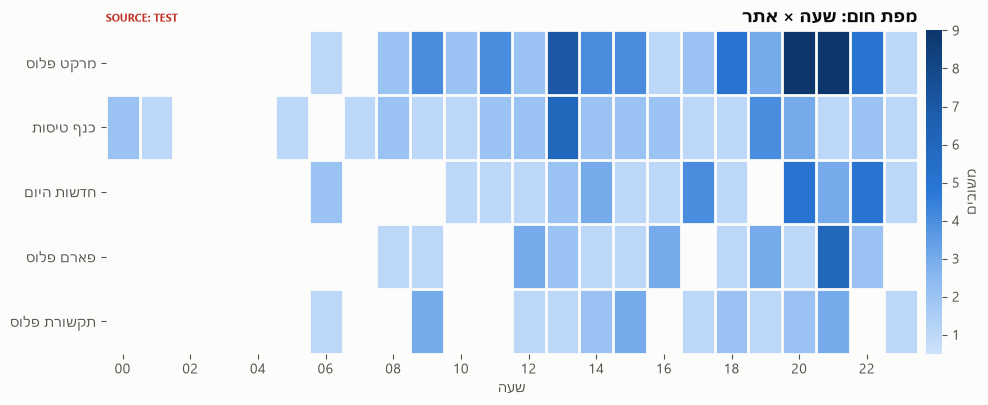

hour,SOURCE,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
site,,,,,,,,,,,,,,,,,,,,,,,,,
מרקט פלוס,TEST,0,0,0,0,0,0,1,0,2,4,2,4,2,7,4,4,1,2,5,3,9,9,5,1
כנף טיסות,TEST,2,1,0,0,0,1,0,1,2,1,1,2,2,6,2,2,2,1,1,4,3,1,2,1
חדשות היום,TEST,0,0,0,0,0,0,2,0,0,0,1,1,1,2,3,1,1,4,1,0,5,3,5,1
פארם פלוס,TEST,0,0,0,0,0,0,0,0,1,1,0,0,3,2,1,1,3,0,1,3,1,6,2,0
תקשורת פלוס,TEST,0,0,0,0,0,0,1,0,0,3,0,0,1,1,2,3,0,1,2,1,2,3,0,1


In [14]:
# Hour × site: where the load concentrates (sequential scale, single hue: light = few, dark = many)
heat = active.pivot_table(index="site", columns="hour", values="id", aggfunc="count", fill_value=0)     .reindex(index=sites_present, columns=range(24), fill_value=0)

fig, ax = plt.subplots(figsize=(10, 0.55 * len(heat) + 1.4))
cmap = SEQ.copy(); cmap.set_bad(SURFACE)  # zero cells = background, not "a little"
im = ax.imshow(np.ma.masked_equal(heat.values, 0), aspect="auto", cmap=cmap, vmin=0.5)
ax.set_xticks(np.arange(-0.5, 24, 1), minor=True); ax.set_yticks(np.arange(-0.5, len(heat), 1), minor=True)
ax.grid(which="minor", color=SURFACE, linewidth=2); ax.tick_params(which="minor", length=0)
ax.set_yticks(range(len(heat)), [h(SITE_NAME.get(s, s)) for s in heat.index])
ax.set_xticks(range(0, 24, 2), [f"{x:02d}" for x in range(0, 24, 2)])
ax.set_xlabel(h("שעה"))
ax.grid(which="major", visible=False)
for spine in ax.spines.values(): spine.set_visible(False)
ax.set_title(h("מפת חום: שעה × אתר"))
cb = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.01); cb.outline.set_visible(False); cb.set_label(h("משובים")); cb.locator = MaxNLocator(integer=True); cb.update_ticks()
source_tag(ax)
plt.tight_layout(); plt.show()
table(heat.rename(index=SITE_NAME))

### 5.2 Sites: volume, distinct users, and trend over time

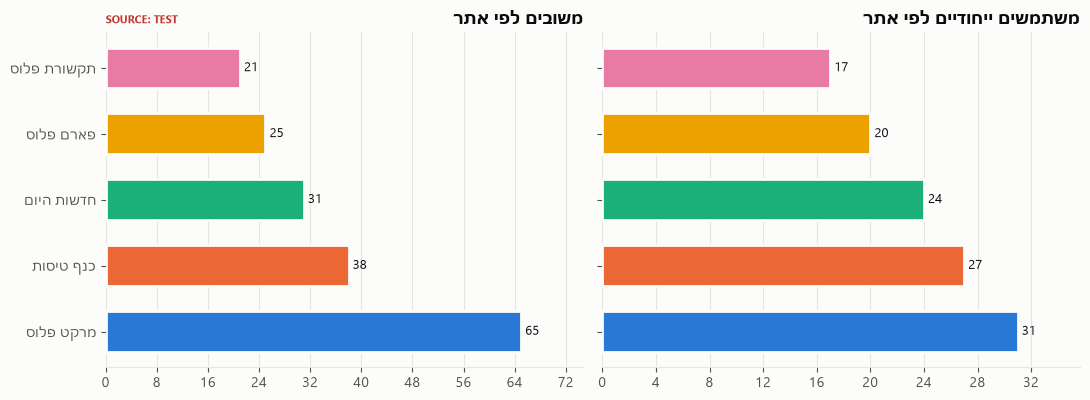

,SOURCE,feedback,distinct_users,feedback_per_user
site,,,,
מרקט פלוס,TEST,65,31,2.10
כנף טיסות,TEST,38,27,1.41
חדשות היום,TEST,31,24,1.29
פארם פלוס,TEST,25,20,1.25
תקשורת פלוס,TEST,21,17,1.24


In [15]:
per_site = active.groupby("site").agg(feedback=("id", "count"), distinct_users=("end_user", "nunique"))     .reindex(sites_present).fillna(0).astype(int)
per_site["feedback_per_user"] = (per_site["feedback"] / per_site["distinct_users"].where(per_site["distinct_users"] > 0)).round(2)

# Two separate charts (two measures → two charts, no dual axis)
fig, axes = plt.subplots(1, 2, figsize=(11, 0.5 * len(per_site) + 1.6), sharey=True)
labels = [h(SITE_NAME.get(s, s)) for s in per_site.index]
colors = [SITE_COLOR[s] for s in per_site.index]
for ax, col, title in [(axes[0], "feedback", "משובים לפי אתר"), (axes[1], "distinct_users", "משתמשים ייחודיים לפי אתר")]:
    bars = ax.barh(labels, per_site[col], color=colors, edgecolor=SURFACE, linewidth=2, height=0.62)
    ax.bar_label(bars, padding=3, fontsize=9, color=INK)
    ax.set_title(h(title)); ax.grid(axis="y", visible=False); ax.invert_yaxis()
    ax.margins(x=0.15); ax.xaxis.set_major_locator(MaxNLocator(integer=True))
source_tag(axes[0])
plt.tight_layout(); plt.show()
table(per_site.rename(index=SITE_NAME))

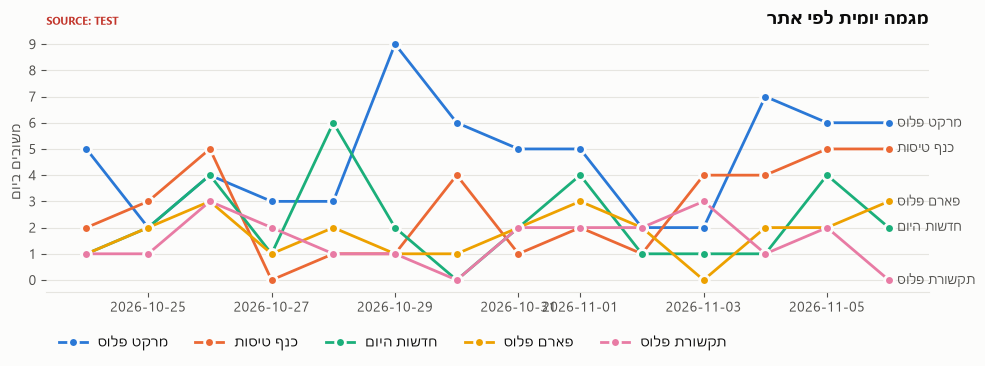

site,SOURCE,מרקט פלוס,כנף טיסות,חדשות היום,פארם פלוס,תקשורת פלוס
day,,,,,,
2026-10-24,TEST,5,2,1,1,1
2026-10-25,TEST,2,3,2,2,1
2026-10-26,TEST,4,5,4,3,3
2026-10-27,TEST,3,0,1,1,2
2026-10-28,TEST,3,1,6,2,1
2026-10-29,TEST,9,1,2,1,1
2026-10-30,TEST,6,4,0,1,0
2026-10-31,TEST,5,1,2,2,2
2026-11-01,TEST,5,2,4,3,2


In [16]:
# Daily trend per site (line per site; legend + label at the end of each line)
daily = active.groupby(["day", "site"]).size().unstack(fill_value=0).reindex(columns=sites_present, fill_value=0)

fig, ax = plt.subplots(figsize=(10, 3.8))
for s in daily.columns:
    ax.plot(daily.index, daily[s], color=SITE_COLOR[s], linewidth=2, marker="o", markersize=7,
            markeredgecolor=SURFACE, markeredgewidth=2, label=h(SITE_NAME.get(s, s)))
    if len(daily) > 1:
        ax.annotate(h(SITE_NAME.get(s, s)), (daily.index[-1], daily[s].iloc[-1]), xytext=(6, 0),
                    textcoords="offset points", va="center", fontsize=9, color=INK_2)
ax.set_ylabel(h("משובים ביום")); ax.yaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_title(h("מגמה יומית לפי אתר"))
ax.legend(frameon=False, ncols=min(5, len(daily.columns)), loc="upper left", bbox_to_anchor=(0, -0.12))
ax.grid(axis="x", visible=False)
if len(daily) == 1:
    ax.text(0.5, 0.5, h("כל הנתונים מיום אחד — המגמה תתמלא עם הזמן"), transform=ax.transAxes,
            ha="center", color=INK_2, fontsize=9)
source_tag(ax)
plt.tight_layout(); plt.show()
table(daily.rename(columns=SITE_NAME))

### 5.3 Content: topics, sentiment and frequent words

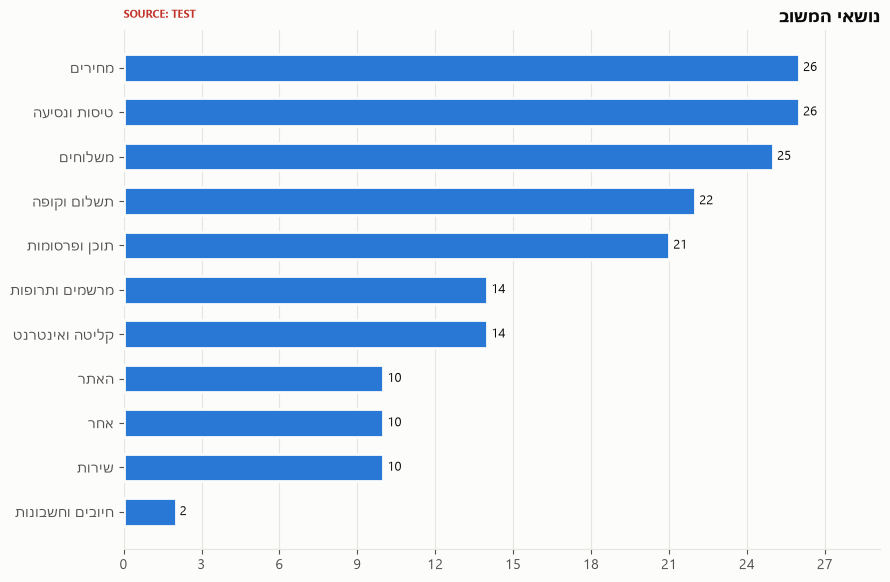

site,SOURCE,חדשות היום,כנף טיסות,מרקט פלוס,פארם פלוס,תקשורת פלוס
category,,,,,,
אחר,TEST,8,2,0,0,0
האתר,TEST,2,0,8,0,0
חיובים וחשבונות,TEST,0,0,0,0,2
טיסות ונסיעה,TEST,0,26,0,0,0
מחירים,TEST,0,7,11,7,1
מרשמים ותרופות,TEST,0,0,0,14,0
משלוחים,TEST,0,0,21,4,0
קליטה ואינטרנט,TEST,0,0,0,0,14
שירות,TEST,0,0,6,0,4


In [17]:
CATEGORY_HE = {"checkout": "תשלום וקופה", "travel": "טיסות ונסיעה", "delivery": "משלוחים", "prices": "מחירים",
               "billing": "חיובים וחשבונות", "connectivity": "קליטה ואינטרנט", "pharmacy": "מרשמים ותרופות",
               "content": "תוכן ופרסומות", "site": "האתר", "service": "שירות", "other": "אחר"}
cats = active["category"].fillna("other").value_counts()

fig, ax = plt.subplots(figsize=(9, 0.42 * len(cats) + 1.3))
bars = ax.barh([h(CATEGORY_HE.get(c, c)) for c in cats.index], cats.values, color=SERIES[0],
               edgecolor=SURFACE, linewidth=2, height=0.62)
ax.bar_label(bars, padding=3, fontsize=9, color=INK)
ax.invert_yaxis(); ax.grid(axis="y", visible=False); ax.margins(x=0.12); ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_title(h("נושאי המשוב"))
source_tag(ax)
plt.tight_layout(); plt.show()
table(pd.crosstab(active["category"].fillna("other").map(CATEGORY_HE), active["site"].map(SITE_NAME)))

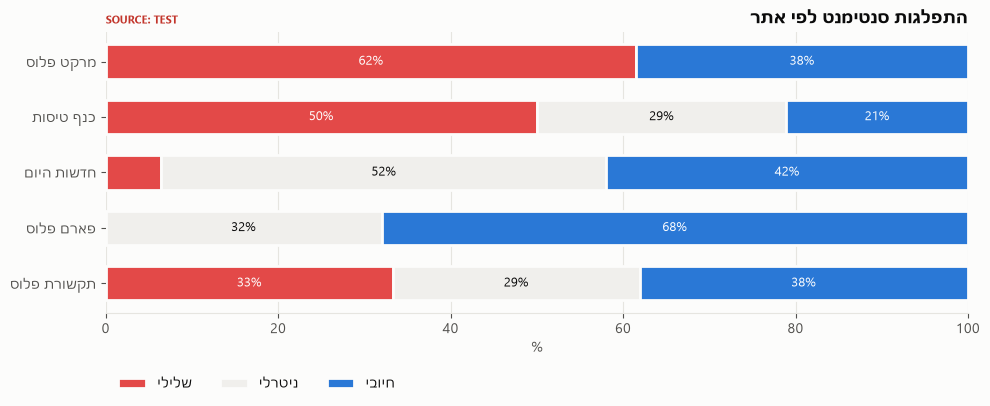

sentiment,SOURCE,negative,neutral,positive
site,,,,
מרקט פלוס,TEST,40,0,25
כנף טיסות,TEST,19,11,8
חדשות היום,TEST,2,16,13
פארם פלוס,TEST,0,8,17
תקשורת פלוס,TEST,7,6,8


In [18]:
# Sentiment by site: 100% stacked bars, diverging (negative ↔ neutral ↔ positive)
sent = pd.crosstab(active["site"], active["sentiment"]).reindex(index=sites_present, columns=["negative", "neutral", "positive"], fill_value=0)
share = sent.div(sent.sum(axis=1).where(lambda x: x > 0), axis=0).fillna(0) * 100

fig, ax = plt.subplots(figsize=(10, 0.55 * len(share) + 1.5))
left = pd.Series(0.0, index=share.index)
labels = [h(SITE_NAME.get(s, s)) for s in share.index]
for col, color, name in [("negative", NEG, "שלילי"), ("neutral", NEU, "ניטרלי"), ("positive", POS, "חיובי")]:
    ax.barh(labels, share[col], left=left, color=color, edgecolor=SURFACE, linewidth=2, height=0.62, label=h(name))
    for i, (v, l0) in enumerate(zip(share[col], left)):
        if v >= 12:
            ax.text(l0 + v / 2, i, f"{v:.0f}%", ha="center", va="center", fontsize=9,
                    color="#ffffff" if col != "neutral" else INK)
    left += share[col]
ax.set_xlim(0, 100); ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.set_xlabel("%"); ax.set_title(h("התפלגות סנטימנט לפי אתר"))
ax.legend(frameon=False, ncols=3, loc="upper left", bbox_to_anchor=(0, -0.18))
source_tag(ax)
plt.tight_layout(); plt.show()
table(sent.rename(index=SITE_NAME))

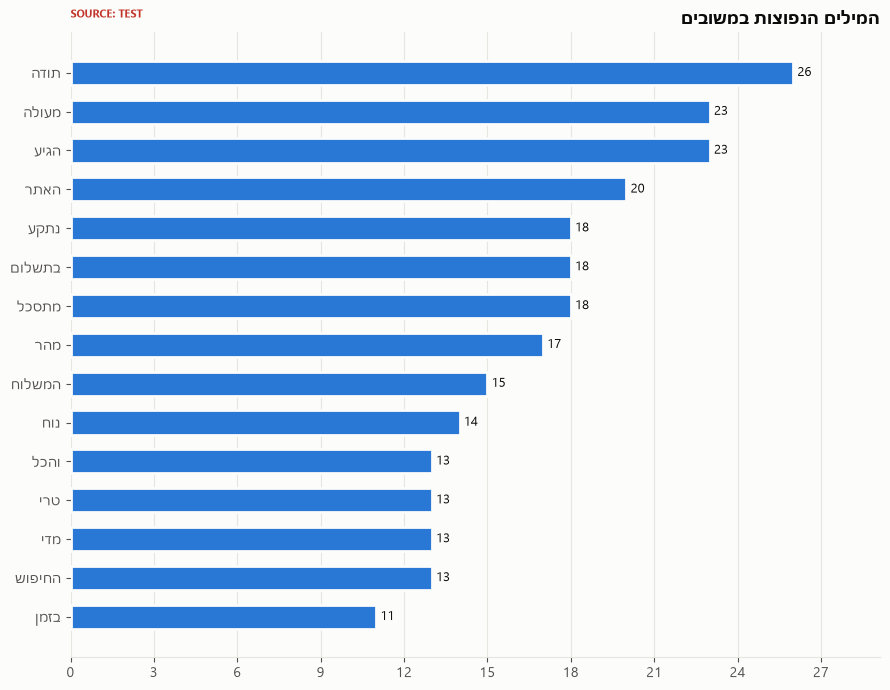

,SOURCE,תודה,מעולה,הגיע,האתר,נתקע,בתשלום,מתסכל,מהר,המשלוח,נוח,והכל,טרי,מדי,החיפוש,בזמן
count,TEST,26,23,23,20,18,18,18,17,15,14,13,13,13,13,11


In [19]:
# Most frequent words in the content (without stop words, QA identifiers and numbers)
STOP = set("של את על עם זה זו לא כן גם אבל או אם כי הוא היא הם הן אני אנחנו אתם יש אין היה היתה היו להיו מאוד ממש רק עוד כל מה איך למה כמו אחרי לפני תוך בלי כבר שלי שלכם האם".split())
words = Counter(
    w for text in active["content"].dropna()
    for w in re.findall(r"[֐-׿A-Za-z]{3,}", re.sub(r"QA-\S+", " ", text))
    if w not in STOP and not w.startswith("QA")
)
top = pd.Series(dict(words.most_common(15)), dtype=int)

if top.empty:
    print("Not enough text to analyze yet")
else:
    fig, ax = plt.subplots(figsize=(9, 0.38 * len(top) + 1.3))
    bars = ax.barh([h(w) for w in top.index], top.values, color=SERIES[0], edgecolor=SURFACE, linewidth=2, height=0.62)
    ax.bar_label(bars, padding=3, fontsize=9, color=INK)
    ax.invert_yaxis(); ax.grid(axis="y", visible=False); ax.margins(x=0.12); ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.set_title(h("המילים הנפוצות במשובים"))
    source_tag(ax)
    plt.tight_layout(); plt.show()
    table(top.rename("count").to_frame().T)

### 5.4 Who are the users: distinct users and device context

53 distinct users · 180 feedback items · average 3.4 per user


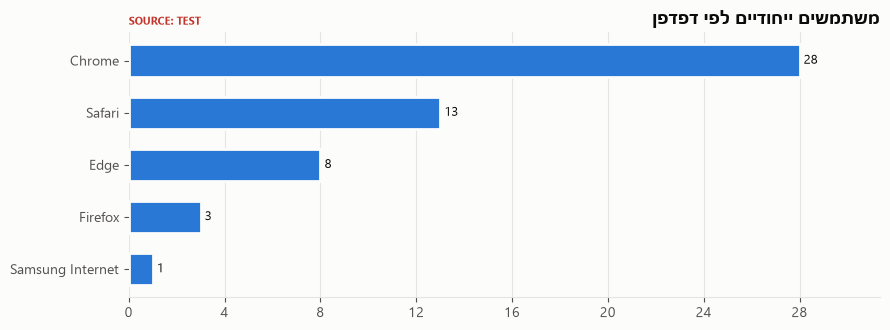

,SOURCE,feedback,sites,first,last,browser,os,device,country,ip_hash
end_user,,,,,,,,,,
00fb8673-8b42-4c83-5484-f3e32248c1e8,TEST,20,5,2026-10-25T13:27:13.000Z,2026-11-05T18:26:27.000Z,Chrome,Windows,desktop,IL,f9ed025601c567fb
b5522e53-a50a-4e8d-ae18-aefd9ff8d085,TEST,9,5,2026-10-24T11:12:23.000Z,2026-11-01T19:50:24.000Z,Chrome,Windows,desktop,IL,cf8d6ab84300fda0
6bc30c42-82d4-49ca-b36d-e45a09e593c4,TEST,8,4,2026-10-25T19:11:04.000Z,2026-11-04T09:48:26.000Z,Chrome,Android,mobile,IL,5a883bc7358b18f8
ce26bc86-ff2a-4397-86a9-d13d1d5a5c32,TEST,6,3,2026-10-26T16:36:00.000Z,2026-11-06T12:29:15.000Z,Safari,iOS,mobile,IL,1f1a82cea0293462
b54c5c09-937a-4e40-9700-62abccc8ee8f,TEST,6,3,2026-10-24T18:06:20.000Z,2026-11-05T13:06:08.000Z,Firefox,Windows,desktop,IL,ec7647fb5cbab9d1
40e1b290-f634-4933-01cd-5deb3a018434,TEST,5,4,2026-10-26T07:34:48.000Z,2026-11-06T17:32:51.000Z,Edge,Windows,desktop,IL,c395b8d3673dab80
99bf4fac-9d2f-4892-63dd-baf9bf739cd3,TEST,5,3,2026-11-03T16:04:13.000Z,2026-11-05T11:18:39.000Z,Chrome,Windows,desktop,IL,8247720201ef0267
fd02c11e-494c-4b07-f116-cb4717682c4b,TEST,5,3,2026-10-25T19:19:40.000Z,2026-11-06T17:14:21.000Z,Edge,Windows,desktop,IL,2be4da511fb48186
edfc7551-7315-484a-ff1e-dbd7ced52600,TEST,5,2,2026-10-24T13:19:49.000Z,2026-11-06T18:09:26.000Z,Edge,Windows,desktop,IL,363eb5f5498fd0df


In [20]:
ctx = active.assign(
    browser=active["browser"].fillna("לא ידוע (לפני האיסוף)"),
    device=active["device"].fillna("לא ידוע"),
    country=active["country"].fillna("לא ידוע"),
)
users = ctx.groupby("end_user").agg(
    feedback=("id", "count"), sites=("site", "nunique"), first=("created_at", "min"), last=("created_at", "max"),
    browser=("browser", "last"), os=("os", "last"), device=("device", "last"), country=("country", "last"),
    ip_hash=("ip_hash", "last"),
).sort_values("feedback", ascending=False)
print(f"{len(users)} distinct users · {len(active)} feedback items · average {len(active) / max(len(users), 1):.1f} per user")

browser_users = ctx.groupby("browser")["end_user"].nunique().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(9, 0.42 * len(browser_users) + 1.3))
bars = ax.barh([h(b) for b in browser_users.index], browser_users.values, color=SERIES[0],
               edgecolor=SURFACE, linewidth=2, height=0.62)
ax.bar_label(bars, padding=3, fontsize=9, color=INK)
ax.invert_yaxis(); ax.grid(axis="y", visible=False); ax.margins(x=0.12); ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_title(h("משתמשים ייחודיים לפי דפדפן"))
source_tag(ax)
plt.tight_layout(); plt.show()
table(users.head(25))

## 6. Data dictionary
| Field | Meaning |
|---|---|
| `SOURCE` | Where the data comes from. Always `TEST` here (the local TEST DB) |
| `type` | `text` / `voice` |
| `content` | The feedback text, or the transcript of a recording (empty if there was no transcript) |
| `rating` | 1–5, text feedback only (optional) |
| `sentiment` / `category` | The result of the local keyword-based analysis (not AI) |
| `audio_path` | The recording file in `data/audio/` |
| `page_url` | The page address without query parameters (data minimization) |
| `consent_version` / `consent_at` | The privacy-notice version the user agreed to, and when |
| `end_user` | Random anonymous identifier of the browser (not a name, email or IP). The same `end_user` = the same author |
| `browser` / `os` / `device` | A summary of the User-Agent only (e.g. Chrome · Windows · desktop); the full string isn't stored |
| `language` / `time_zone` | Browser language and time zone (e.g. `he-IL`, `Asia/Jerusalem`) |
| `country` | Estimated from the time zone, otherwise from the language region (no geolocation) |
| `feedback_lang` | The language the user chose in the widget: `he` / `en` / `ar` |
| `ip_hash` | One-way HMAC-SHA256 fingerprint of the IP address (the address itself isn't stored). Locally it's always the same value, because everything comes from 127.0.0.1 |
| `site_active` | 0 = a site removed from `sites.json` (its data is kept) |

Retention: rows older than 90 days are deleted automatically by the server.

In [21]:
conn.close()
print("The connection to the TEST DB is closed.")

The connection to the TEST DB is closed.
